=== NEWMAN SPECTRAL BISECTION OUTPUT ===

Iteration 0: 1 Community(s) | Global Q = -0.000000
  Community 1 (34 nodes): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]

Iteration 1: 2 Community(s) | Global Q = 0.371466
  Community 1 (16 nodes): [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
  Community 2 (18 nodes): [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]

Iteration 2: 4 Community(s) | Global Q = 0.393409
  Community 1 ( 7 nodes): [0, 4, 5, 6, 10, 11, 16]
  Community 2 ( 9 nodes): [1, 2, 3, 7, 12, 13, 17, 19, 21]
  Community 3 (12 nodes): [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
  Community 4 ( 6 nodes): [23, 24, 25, 27, 28, 31]


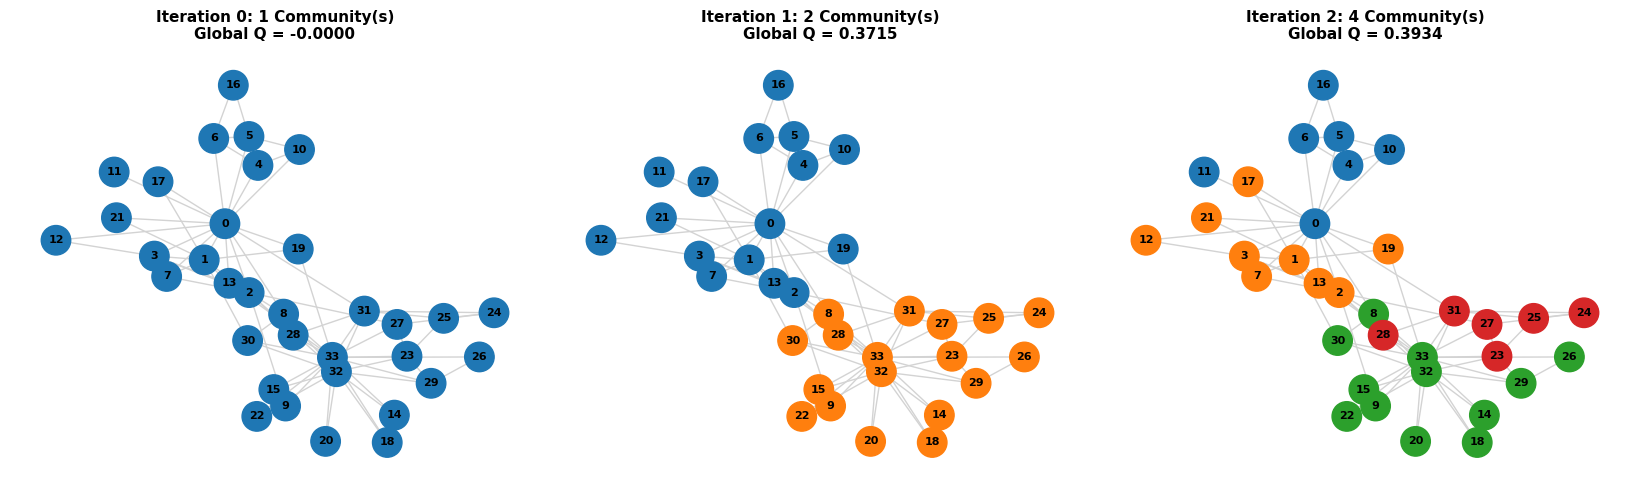

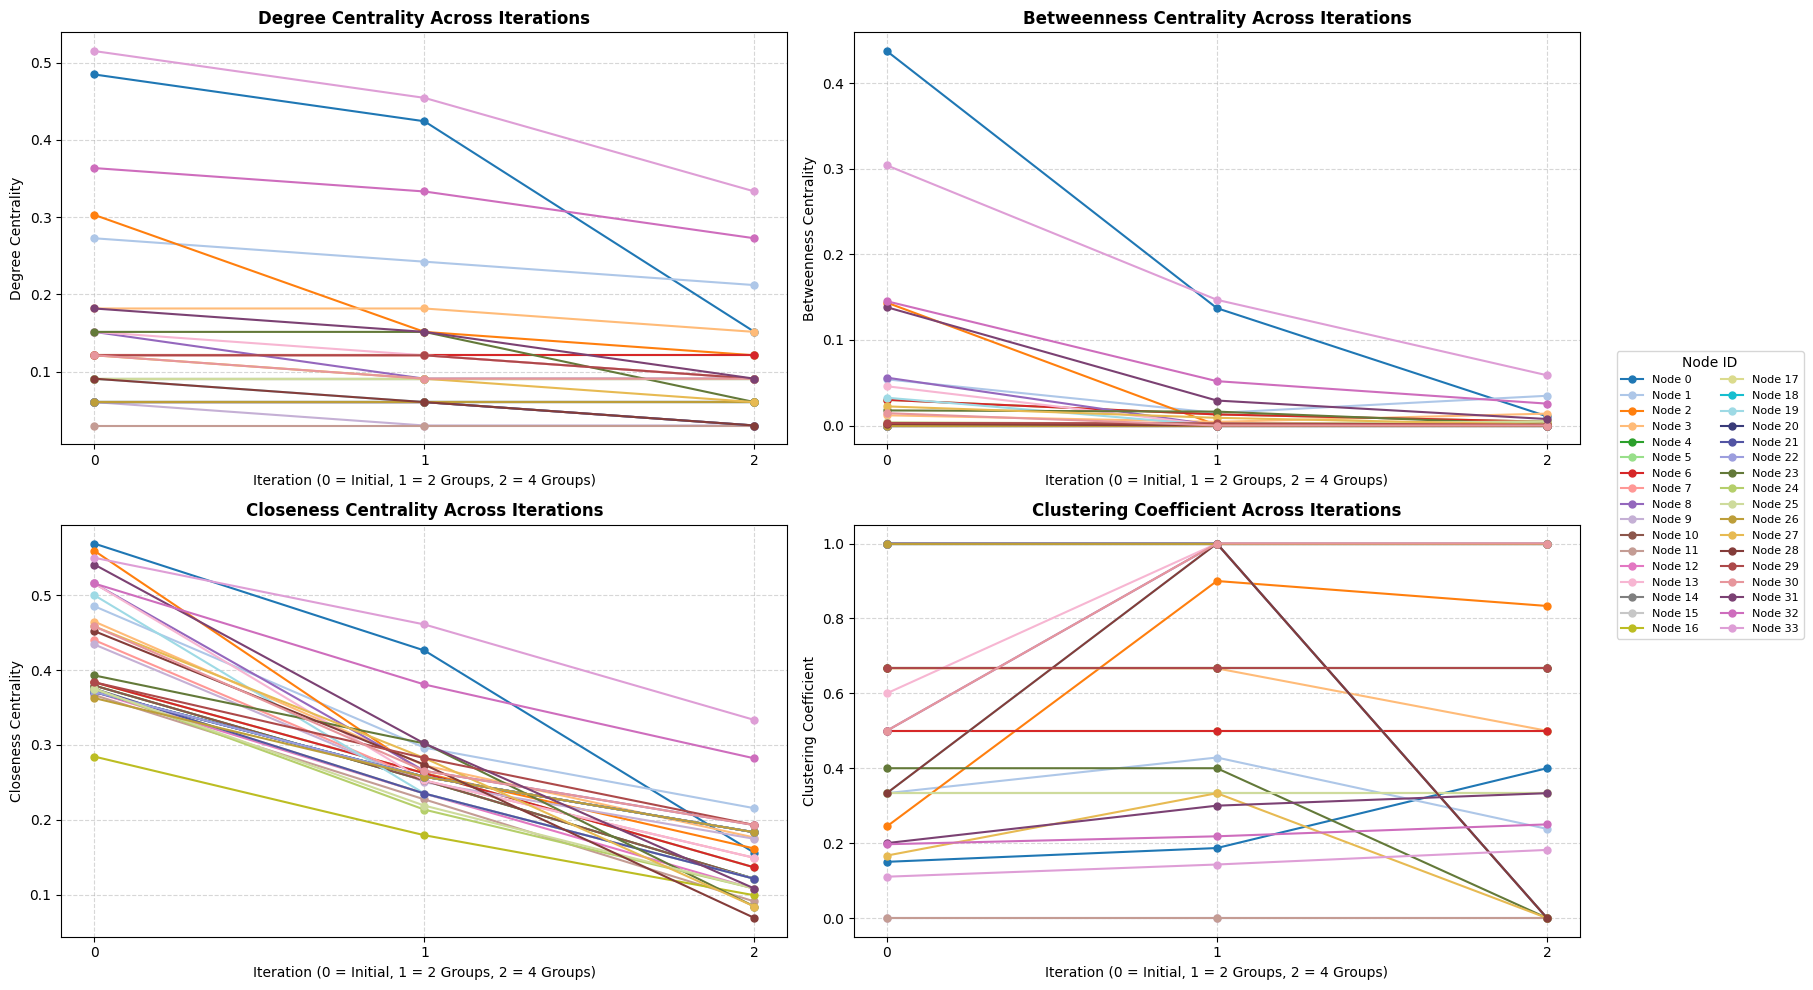

=== Iteration 0 (1 Communities) ===
Node   | Degree     | Betweenness  | Closeness  | Clustering
----------------------------------------------------------
0      | 0.4848     | 0.4376       | 0.5690     | 0.1500    
1      | 0.2727     | 0.0539       | 0.4853     | 0.3333    
2      | 0.3030     | 0.1437       | 0.5593     | 0.2444    
3      | 0.1818     | 0.0119       | 0.4648     | 0.6667    
4      | 0.0909     | 0.0006       | 0.3793     | 0.6667    
5      | 0.1212     | 0.0300       | 0.3837     | 0.5000    
6      | 0.1212     | 0.0300       | 0.3837     | 0.5000    
7      | 0.1212     | 0.0000       | 0.4400     | 1.0000    
8      | 0.1515     | 0.0559       | 0.5156     | 0.5000    
9      | 0.0606     | 0.0008       | 0.4342     | 0.0000    
10     | 0.0909     | 0.0006       | 0.3793     | 0.6667    
11     | 0.0303     | 0.0000       | 0.3667     | 0.0000    
12     | 0.0606     | 0.0000       | 0.3708     | 1.0000    
13     | 0.1515     | 0.0459       | 0.5156     | 0

In [ ]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# Setup: Load Graph, Build Global B, and Define Q
# ==========================================
G = nx.karate_club_graph()
n = G.number_of_nodes()  # 34 nodes
m = G.number_of_edges()  # 78 edges

# Lock node positions once so visual comparisons across iterations stay aligned
pos = nx.spring_layout(G, seed=42)

# Build unweighted Adjacency Matrix A and Global Modularity Matrix B
A = nx.to_numpy_array(G, weight=None)
k = A.sum(axis=1, keepdims=True)
B = A - (k @ k.T) / (2.0 * m)

def modularity(communities):
    """Computes global modularity Q using vectorized NumPy broadcasting."""
    label = np.zeros(n, dtype=int)
    for c, C in enumerate(communities):
        label[C] = c
    same = label[:, None] == label[None, :]
    return (B * same).sum() / (2.0 * m)


# ==========================================
# Task 1: Recursive Spectral Modularity Partitioning
# ==========================================
def newman_spectral_split(nodes):
    """Splits community C using Newman's generalized modularity matrix B^(g)."""
    if len(nodes) <= 1:
        return [nodes], False

    # Slice the global modularity matrix B for nodes in C
    idx = np.array(nodes)
    B_sub = B[np.ix_(idx, idx)].copy()

    # Apply Newman's exact diagonal correction: B^(g)_ij = B_ij - delta_ij * sum_{l in C} B_il
    B_g = B_sub - np.diag(B_sub.sum(axis=1))

    # Find leading eigenpair (lambda_1, u_1)
    eigenvalues, eigenvectors = np.linalg.eigh(B_g)
    lambda_1 = eigenvalues[-1]
    u_1 = eigenvectors[:, -1]

    # Stopping criterion 1: If leading eigenvalue <= 0, group is indivisible
    if lambda_1 <= 1e-10:
        return [nodes], False

    # Split nodes into C+ and C- by the sign of u_1
    c_plus = [nodes[i] for i in range(len(nodes)) if u_1[i] > 0]
    c_minus = [nodes[i] for i in range(len(nodes)) if u_1[i] <= 0]

    if len(c_plus) == 0 or len(c_minus) == 0:
        return [nodes], False

    # Stopping criterion 2: Verify positive discrete modularity gain (Delta Q > 0)
    s = np.where(u_1 > 0, 1.0, -1.0)
    delta_q = (s.T @ B_g @ s) / (4.0 * m)
    if delta_q <= 1e-10:
        return [nodes], False

    return [c_plus, c_minus], True


# Run level-by-level recursive bisection and store metrics at each iteration
communities = [list(G.nodes())]
community_history = [list(communities)]
q_history = {}

degree_history = {}
betweenness_history = {}
closeness_history = {}
clustering_history = {}

iteration = 0
print("=== NEWMAN SPECTRAL BISECTION OUTPUT ===")

while True:
    q_val = modularity(communities)
    q_history[iteration] = q_val
    print(f"\nIteration {iteration}: {len(communities)} Community(s) | Global Q = {q_val:.6f}")
    for c_idx, comm in enumerate(communities, 1):
        print(f"  Community {c_idx} ({len(comm):2d} nodes): {sorted(comm)}")

    # Build partitioned graph containing only intra-community edges
    G_part = nx.Graph()
    G_part.add_nodes_from(G.nodes())
    for comm in communities:
        G_part.add_edges_from(G.subgraph(comm).edges())

    # Task 3: Compute standard node metrics after each split
    degree_history[iteration] = nx.degree_centrality(G_part)
    betweenness_history[iteration] = nx.betweenness_centrality(G_part)
    closeness_history[iteration] = nx.closeness_centrality(G_part)
    clustering_history[iteration] = nx.clustering(G_part)

    # Attempt to split every active community
    next_communities = []
    any_split = False
    for comm in communities:
        parts, did_split = newman_spectral_split(comm)
        next_communities.extend(parts)
        if did_split:
            any_split = True

    if not any_split:
        break

    communities = next_communities
    community_history.append(list(communities))
    iteration += 1


# ==========================================
# Task 2: Visualize Graph After Each Split
# ==========================================
num_iters = len(community_history)
fig, axes = plt.subplots(1, num_iters, figsize=(5.5 * num_iters, 5))
if num_iters == 1:
    axes = [axes]

cmap = plt.get_cmap("tab10")

for it, comms in enumerate(community_history):
    ax = axes[it]
    color_lookup = {}
    for c_idx, comm in enumerate(comms):
        for node in comm:
            color_lookup[node] = cmap(c_idx % 10)
    node_colors = [color_lookup[node] for node in G.nodes()]

    nx.draw(
        G,
        pos=pos,
        ax=ax,
        with_labels=True,
        node_color=node_colors,
        node_size=450,
        font_size=8,
        font_weight="bold",
        edge_color="lightgray"
    )
    ax.set_title(
        f"Iteration {it}: {len(comms)} Community(s)\nGlobal Q = {q_history[it]:.4f}",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()


# ==========================================
# Task 4: Plot Evolution of Metrics for Every Node
# ==========================================
metrics_bundle = [
    ("Degree Centrality", degree_history),
    ("Betweenness Centrality", betweenness_history),
    ("Closeness Centrality", closeness_history),
    ("Clustering Coefficient", clustering_history)
]

iterations = sorted(q_history.keys())
all_nodes = sorted(G.nodes())

node_palette = np.vstack([
    plt.get_cmap("tab20")(np.linspace(0, 1, 20)),
    plt.get_cmap("tab20b")(np.linspace(0, 1, 14))
])

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for idx, (title, metric_dict) in enumerate(metrics_bundle):
    ax = axes[idx]
    for node in all_nodes:
        y_vals = [metric_dict[it][node] for it in iterations]
        ax.plot(
            iterations,
            y_vals,
            marker="o",
            markersize=5,
            linewidth=1.5,
            color=node_palette[node],
            label=f"Node {node}"
        )

    ax.set_title(f"{title} Across Iterations", fontsize=12, fontweight="bold")
    ax.set_xlabel("Iteration (0 = Initial, 1 = 2 Groups, 2 = 4 Groups)")
    ax.set_ylabel(title)
    ax.set_xticks(iterations)
    ax.grid(True, linestyle="--", alpha=0.5)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title="Node ID",
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    ncol=2,
    fontsize=8
)

plt.tight_layout()
plt.show()











import networkx as nx
import numpy as np

# Load graph
G = nx.karate_club_graph()

# Dictionaries keyed by iteration number to store the 4 metrics
degree_history = {}
betweenness_history = {}
closeness_history = {}
clustering_history = {}

# Loop through the communities saved at each iteration
# (Assumes 'community_history' was generated by your recursive split loop)
for iteration, communities in enumerate(community_history):

    # 1. Build a graph with all 34 nodes, keeping ONLY intra-community edges
    G_part = nx.Graph()
    G_part.add_nodes_from(G.nodes())
    for comm in communities:
        G_part.add_edges_from(G.subgraph(comm).edges())

    # 2. Compute the 4 metrics using NetworkX built-in functions
    degree_history[iteration] = nx.degree_centrality(G_part)
    betweenness_history[iteration] = nx.betweenness_centrality(G_part)
    closeness_history[iteration] = nx.closeness_centrality(G_part)
    clustering_history[iteration] = nx.clustering(G_part)

    # 3. Print a summary of the values for this iteration
    print(f"=== Iteration {iteration} ({len(communities)} Communities) ===")
    print(f"{'Node':<6} | {'Degree':<10} | {'Betweenness':<12} | {'Closeness':<10} | {'Clustering':<10}")
    print("-" * 58)
    for node in sorted(G.nodes()):
        deg = degree_history[iteration][node]
        bet = betweenness_history[iteration][node]
        clo = closeness_history[iteration][node]
        clu = clustering_history[iteration][node]
        print(f"{node:<6} | {deg:<10.4f} | {bet:<12.4f} | {clo:<10.4f} | {clu:<10.4f}")
    print()

